# Beskrivande Analys



# läser datan från hälsostudien


In [24]:
import sys, os
import pandas as pd
import numpy as np  
sys.path.append(os.path.abspath(".."))
from src.io_utils import *


#df = pd.read_csv("file_path)")

print(df.head(10))

   id  age sex  height  weight  systolic_bp  cholesterol smoker  disease
0   1   57   F   168.9    65.8        141.8         4.58     No        0
1   2   47   M   180.4    95.9        144.8         5.18    Yes        0
2   3   59   F   169.9    82.2        151.7         6.16     No        0
3   4   72   M   157.7    93.1        151.0         6.63     No        0
4   5   46   M   192.6   104.1        144.1         5.21     No        0
5   6   46   F   167.6    68.6        153.8         4.91     No        0
6   7   73   M   185.8    83.0        150.0         5.92     No        0
7   8   61   F   168.1    51.5        134.8         5.13    Yes        0
8   9   42   M   182.3    81.7        141.0         4.02     No        0
9  10   58   F   157.1    67.3        159.8         5.38     No        0


#Beräkna medelvärde, median, minimum och maximum för: `ålder`, `vikt`, `längd`, `systoliskt_blodtryck` och `kolesterol`.

In [26]:
import numpy as np
import pandas as pd

columns = ['age', 'height', 'weight', 'systolic_bp', 'cholesterol']
summary=df[columns].agg(['mean', 'median', 'min', 'max'])

print(summary)

             age     height   weight  systolic_bp  cholesterol
mean    49.42625  171.84925   73.413   149.178625      4.92915
median  50.00000  171.35000   73.200   149.400000      4.97000
min     18.00000  144.40000   33.700   106.800000      2.50000
max     90.00000  200.40000  114.400   185.900000      7.88000


#Skapa minst 3 olika diagram (t.ex. ett histogram över blodtryck, ett boxplot över vikt efter kön, eller ett stapeldiagram som visar andelen rökare).

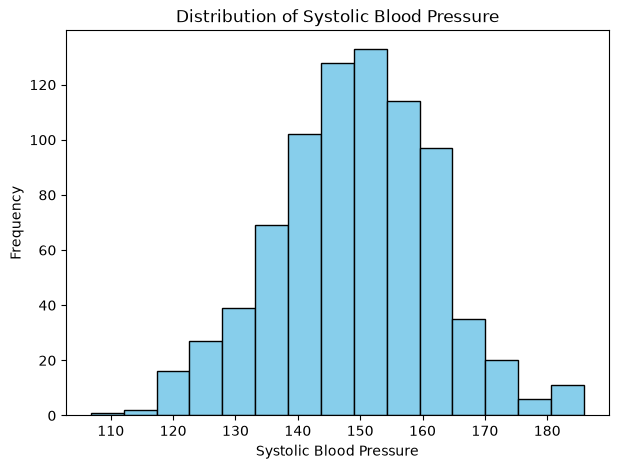

In [29]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.hist(df['systolic_bp'].dropna(), bins=15, color='skyblue', edgecolor='black')
plt.xlabel('Systolic Blood Pressure')
plt.ylabel('Frequency')
plt.title('Distribution of Systolic Blood Pressure')
plt.show()

C:\Users\rvmad\AppData\Local\Temp\ipykernel_96380\948678318.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='sex', y='weight', palette='Set2')


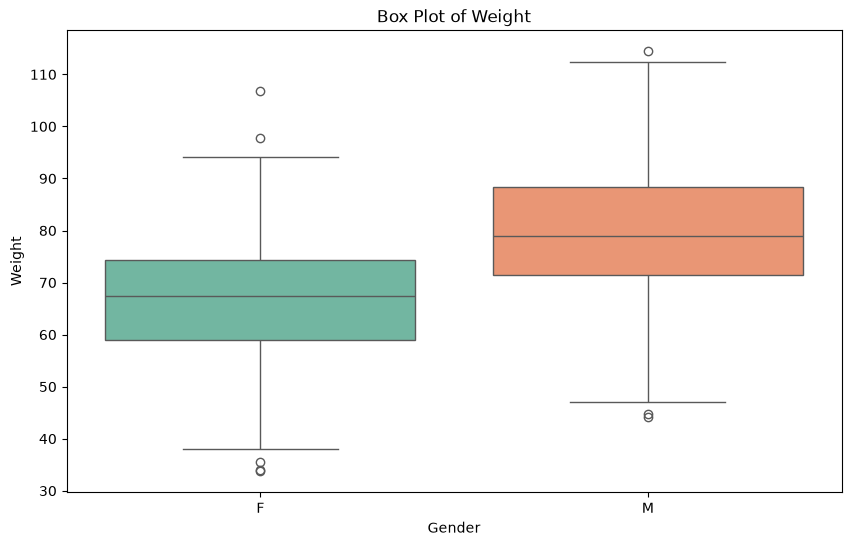

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='sex', y='weight', palette='Set2')
plt.xlabel('Gender')
plt.ylabel('Weight')
plt.title('Box Plot of Weight')
plt.show()

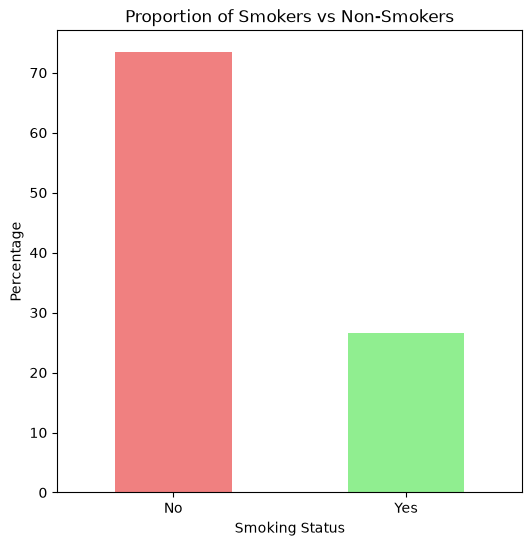

In [34]:
smoker_prop = df['smoker'].value_counts(normalize=True) * 100

plt.figure(figsize=(6, 6))
smoker_prop.plot(kind='bar', color=['lightcoral', 'lightgreen'])
plt.title('Proportion of Smokers vs Non-Smokers')
plt.ylabel('Percentage')
plt.xlabel('Smoking Status')
plt.xticks(rotation=0)
plt.show()

#Simulering relaterad till fallet (använd `numpy.random` + ett seed).
Beräkna andelen individer i datasetet som har sjukdomen.
Använd `numpy` för att simulera 1 000 slumpmässiga individer, och tillämpa samma sannolikhet för att ha sjukdomen.
Jämför den simulerade andelen med den faktiska andelen som finns i datasetet.

In [35]:
disease_prop = df['disease'].mean()

print(f"Proportion of individuals with the disease: {disease_prop:.2%}")

Proportion of individuals with the disease: 5.88%


In [37]:
import numpy as np

np.random.seed(42)  # For reproducibility

p_disease = df['disease'].mean()  # Probability of having the disease

simulated_disease = np.random.choice([0, 1], size=1000, p=[1 - p_disease, p_disease])

simulated_proportion = simulated_disease.mean()

print(f"observed proportion of individuals with the disease: {disease_prop:.2%}")
print(f"Simulated proportion of individuals with the disease: {simulated_proportion:.2%}")
print(f"Difference between observed and simulated proportions: {abs(disease_prop - simulated_proportion):.2%}")

observed proportion of individuals with the disease: 5.88%
Simulated proportion of individuals with the disease: 5.60%
Difference between observed and simulated proportions: 0.27%


# Konfidensintervall
Beräkna ett konfidensintervall för medelvärdet av systolic_bp (t.ex. med normalapproximation eller bootstrap, som vi gått igenom på kursen).

In [51]:
import numpy as np
from math import sqrt

def ci_mean_normal(x, confidence=0.95):
    x=np.asarray(x, dtype=np.float64)
    x = x[~np.isnan(x)]  # Remove NaN values

    n = len(x)
    mean_x = np.mean(x)
    s = np.std(x, ddof=1)  # Sample standard deviation

    se = s / sqrt(n)  # Standard error

    z_score = 1.96  # For 95% confidence

    half_width = z_score * se

    lower = mean_x - half_width
    upper = mean_x + half_width

    return mean_x, lower, upper

mean_bp,lower_ci, upper_ci = ci_mean_normal(df['systolic_bp'])

print(f"Mean Systolic Blood Pressure: {mean_bp:.2f}")
print(f"95% Confidence Interval(Normal approximation): ({lower_ci:.2f}, {upper_ci:.2f})")




Mean Systolic Blood Pressure: 149.18
95% Confidence Interval(Normal approximation): (148.29, 150.07)


In [39]:
from math import sqrt

def ci_mean_bootstrap(x, n_bootstrap=1000, confidence=0.95):
    x = np.asarray(x, dtype=np.float64)
    x = x[~np.isnan(x)]  # Remove NaN values

    np.random.seed(42)  # For reproducibility

    n = len(x)
    boot_means = np.empty(n_bootstrap)

    for i in range(n_bootstrap):
        sample = np.random.choice(x, size=n, replace=True)
        boot_means[i] = np.mean(sample) 

    alpha = 1 - confidence

    lower = np.percentile(boot_means, 100 * (alpha / 2))
    upper = np.percentile(boot_means, 100 * (1 - alpha / 2))

    return x.mean(), lower, upper

mean_bp, lower_ci, upper_ci = ci_mean_bootstrap(df['systolic_bp'])  

print(f"Mean Systolic Blood Pressure: {mean_bp:.2f}")
print(f"95% Confidence Interval (Bootstrap): ({lower_ci:.2f}, {upper_ci:.2f})")

    

   

Mean Systolic Blood Pressure: 149.18
95% Confidence Interval (Bootstrap): (148.31, 150.10)


tolkning:

Det normala approximationskonfidensintervallet och bootstrap-konfidensintervallet var mycket lika, vilket tyder på att stickprovsfördelningen av medelvärdet för systoliskt blodtryck är ungefär normal. Bootstrap-metoden förlitar sig inte på strikta normalitetsantaganden och ger därför en användbar bekräftelse av resultaten från den normala approximationen.

# Hypotesprövning

In [47]:
import numpy as np
from scipy.stats import ttest_ind

smokers = df[df['smoker'] == 'No']['systolic_bp'].dropna()
non_smokers = df[df['smoker'] == 'Yes']['systolic_bp'].dropna()

t_stat, p_value = ttest_ind(smokers, non_smokers, equal_var=False)  # Welch's t-test

print(f"mean_bp_smokers: {smokers.mean():.2f}")
print(f"mean_bp_non_smokers: {non_smokers.mean():.2f}")
print(f"t-statistic: {t_stat:.2f}")
print(f"p-value: {p_value:.2f}")

mean_bp_smokers: 149.05
mean_bp_non_smokers: 149.52
t-statistic: -0.45
p-value: 0.65


#Tolkning

Nollhypotes (H₀): Rökare och icke-rökare har samma genomsnittliga systoliska blodtryck.

Alternativ hypotes (H₁): Rökare har högre genomsnittligt systoliskt blodtryck än icke-rökare.

Resultat:

Genomsnittligt systoliskt blodtryck hos rökare ≈ 149,05
Genomsnittligt systoliskt blodtryck hos icke-rökare ≈ 149,52
t-statistik = -0,45
p-värde = 0,65

Eftersom p-värdet (0,65) är större än signifikansnivån 0,05, kan vi inte förkasta nollhypotesen.

In [ ]:
print(df['smoker'].value_counts(dropna=False))

bp_smokers = df[df['smoker'] == 'No']['systolic_bp'].dropna()
bp_non_smokers = df[df['smoker'] == 'Yes']['systolic_bp'].dropna()

print("Smokers:", len(bp_smokers))
print("Non-smokers:", len(bp_non_smokers))


smoker
No     587
Yes    213
Name: count, dtype: int64
Smokers: 587
Non-smokers: 213


In [46]:
print(df.dtypes)
print(df['smoker'].unique())
print(df['systolic_bp'].head())

id               int64
age              int64
sex                str
height         float64
weight         float64
systolic_bp    float64
cholesterol    float64
smoker             str
disease          int64
dtype: object
<StringArray>
['No', 'Yes']
Length: 2, dtype: str
0    141.8
1    144.8
2    151.7
3    151.0
4    144.1
Name: systolic_bp, dtype: float64


# 